# Experimento 3 · Filtrado basado en contenido

**Idea.** Recomendar películas mexicanas *parecidas* a las que el usuario ya disfrutó, donde "parecido" se mide con el contenido de la película (sinopsis, géneros, década y director), sin mirar lo que hicieron otros usuarios. Es el complemento natural del filtrado colaborativo: no depende de que la película tenga muchas vistas, así que puede recomendar cine mexicano poco conocido.

**Pregunta.** ¿Qué tan bien recomienda el contenido frente al filtrado colaborativo, para el espectador ocasional (grupo 3–4) y el asiduo (grupo ≥ 5)? ¿Ayuda el sentimiento de las reseñas a construir un mejor perfil del usuario?

**Diseño.** Se usan exactamente los mismos usuarios, partición y métricas que en los experimentos 1 y 2, para que los resultados sean comparables directamente.

| Representación del texto | Cómo | Dónde corre |
|---|---|---|
| **TF-IDF** | unigramas y bigramas de la sinopsis limpia (inglés, sin *stopwords*) | CPU, segundos |
| **Embeddings** | `paraphrase-multilingual-MiniLM-L12-v2` (sentence-transformers), 384 dimensiones | CPU/GPU; se calculan una vez y se guardan en `datos/limpios/embeddings/` |

A ambas se les pueden sumar bloques one-hot de **géneros** (IMDb), **década** y **directores** (solo conocidos para el catálogo mexicano).

**Perfil del usuario.** Suma de los vectores de las películas que vio, con peso `w = p − 0.5` (lo que calificó alto acerca el perfil; lo que calificó bajo lo aleja). Las películas mexicanas vistas pesan `peso_mx` veces más que el resto del historial. El puntaje de cada candidata es la similitud coseno con el perfil.

**Modelos.** `Contenido-TFIDF` y `Contenido-Embeddings` usan texto + metadatos; las versiones `(solo texto)` usan únicamente la sinopsis y sirven para medir cuánto aporta el texto por sí solo.

| Variante | Señal | Requiere |
|---|---|---|
| **A** | solo estrellas / *like* | — |
| **B** | + sentimiento BETO | notebook 04 |
| **C** | + sentimiento JEV | notebook 05 |

In [1]:
# --- Configuración del entorno ---------------------------------------------
# En la Mac no hay que cambiar nada. En Colab u otro servidor: sube la carpeta
# TT_Recomendador_Cine_Mexicano (basta con src/ y datos/limpios/) y descomenta:
# from google.colab import drive
# drive.mount('/content/drive')
# import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano


In [2]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from recomendador import rutas, modelos_cf as cf, modelos_contenido as cb, experimento as E

SALIDA = rutas.carpeta_resultados('exp3')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
cat = E.cargar_catalogo()
catalogo = pd.Index(cat['item'])
items = pd.read_parquet(rutas.LIMPIOS / 'items_contenido.parquet')
similitud = E.similitud_catalogo(cat)
print(f'{len(items):,} películas con información de contenido; {int((items.sinopsis != "").sum()):,} con sinopsis informativa')

98,798 películas con información de contenido; 51,466 con sinopsis informativa


## 1. Representación 2: embeddings de las sinopsis

Las sinopsis ya vienen limpias del notebook 00 (sin HTML, URLs, créditos ni textos de relleno). Si el archivo de embeddings no existe y `sentence-transformers` está instalado, se calcula aquí (~2 min en GPU, ~5–10 min en una Mac con MPS). Si no se puede, el experimento continúa solo con TF-IDF.

In [3]:
MODELO_EMBEDDINGS = 'sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2'
RUTA_EMB = rutas.LIMPIOS / 'embeddings' / f"sinopsis_{MODELO_EMBEDDINGS.split('/')[-1]}.npz"

if not RUTA_EMB.exists():
    try:
        import torch
        dispositivo = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
        print('Calculando embeddings en', dispositivo, '…')
        cb.calcular_embeddings(items, MODELO_EMBEDDINGS, RUTA_EMB, dispositivo=dispositivo)
    except ImportError:
        print('sentence-transformers no está instalado: pip install sentence-transformers. Se sigue solo con TF-IDF.')
HAY_EMBEDDINGS = RUTA_EMB.exists()
print('Embeddings disponibles:', HAY_EMBEDDINGS, '→', RUTA_EMB.name if HAY_EMBEDDINGS else '')

Embeddings disponibles: True → sinopsis_paraphrase-multilingual-MiniLM-L12-v2.npz


In [4]:
# Representaciones en caché: se construyen una vez por combinación de pesos
_REPS = {}
def representacion(texto, generos, decada, directores):
    clave = (texto, generos, decada, directores)
    if clave not in _REPS:
        pesos = dict(peso_generos=generos, peso_decada=decada, peso_directores=directores)
        rep = cb.RepresentacionTFIDF(**pesos) if texto == 'tfidf' else cb.RepresentacionEmbeddings(RUTA_EMB, **pesos)
        _REPS[clave] = rep.ajustar(items)
    return _REPS[clave]

def fabrica(texto):
    def crear(p):
        rep = representacion(texto, p['generos'], p['decada'], p['directores'])
        return cb.PerfilContenido(rep, p['centrado'], p['peso_mx'])
    return crear

# Rejilla final. En un barrido previo (ver docs/Experimento_3.md) el centrado por usuario fue
# siempre peor que el neutral y sin metadatos el modelo quedaba por debajo de popularidad.
REJILLA = [dict(generos=g, decada=d, directores=di, centrado='neutral', peso_mx=w)
           for g in (0.3, 0.6) for d in (0.25, 0.5, 1.0) for di in (1.0, 2.0) for w in (50, 200, 1000)]
# Referencia sin metadatos (solo el texto de la sinopsis), para medir cuánto aporta el texto por sí solo
SOLO_TEXTO = [dict(generos=0, decada=0, directores=0, centrado='neutral', peso_mx=w) for w in (50, 200, 1000)]

FAMILIAS = {'Popularidad': (lambda p: cf.Popularidad(), [{}]),   # referencia común con los experimentos 1 y 2
            'Contenido-TFIDF (solo texto)': (fabrica('tfidf'), SOLO_TEXTO),
            'Contenido-TFIDF': (fabrica('tfidf'), REJILLA)}
if HAY_EMBEDDINGS:
    FAMILIAS['Contenido-Embeddings (solo texto)'] = (fabrica('emb'), SOLO_TEXTO)
    FAMILIAS['Contenido-Embeddings'] = (fabrica('emb'), REJILLA)
print({k: len(v[1]) for k, v in FAMILIAS.items()}, 'configuraciones por familia')

{'Popularidad': 1, 'Contenido-TFIDF (solo texto)': 3, 'Contenido-TFIDF': 36, 'Contenido-Embeddings (solo texto)': 3, 'Contenido-Embeddings': 36} configuraciones por familia


In [5]:
rep = representacion('tfidf', 0, 0, 0)
print(f'TF-IDF: vocabulario de {rep.vocabulario:,} términos, {rep.V.shape[0]:,} películas')
# Vecinos de contenido de una película conocida, como prueba de cordura
def vecinos(rep, slug, n=6):
    S = cb.similitud_con_catalogo(rep, pd.Index([slug]), catalogo)[0]
    orden = np.argsort(-S)[1:n + 1]
    return cat.iloc[orden][['titulo', 'anio', 'generos']].assign(similitud=S[orden])
ejemplo = 'pans-labyrinth' if 'pans-labyrinth' in catalogo else catalogo[0]
print('Más parecidas a', cat.set_index('item').loc[ejemplo, 'titulo'], '(TF-IDF):')
display(vecinos(rep, ejemplo))
if HAY_EMBEDDINGS:
    print('… y con embeddings:')
    display(vecinos(representacion('emb', 0, 0, 0), ejemplo))

TF-IDF: vocabulario de 50,000 términos, 54,071 películas
Más parecidas a Pan's Labyrinth (TF-IDF):


,titulo,anio,generos,similitud
824,Watch Out for Love,1954,"Comedy,Drama,Western",0.0844
711,Reinvented Mom,2025,Comedy,0.0826
24,Little Boy,2015,"Drama,History,War",0.0643
515,Condones.com,2009,Comedy,0.0541
645,Mi Maestra se comió a mi amigo,2023,"Adventure,Comedy,Family",0.0516
863,Let's Go with Pancho Villa!,1936,"Action,Adventure,Drama",0.0516


… y con embeddings:


,titulo,anio,generos,similitud
124,Come Play With Me,2021,"Fantasy,Horror,Thriller",0.5900
139,Alucarda,1977,Horror,0.5870
638,Aurora,2021,Drama,0.5867
510,Aunt Alejandra,1980,"Drama,Horror,Mystery",0.5674
415,Double Pregnant 2,2022,Comedy,0.5660
780,The Phantom of the Monastery,1934,"Adventure,Drama,Horror",0.5638


## 2. Ajuste, evaluación y variantes — para cada grupo

In [6]:
FAMILIAS_SENT = {n: f for n, f in FAMILIAS.items() if n in ('Contenido-TFIDF', 'Contenido-Embeddings')}
CODIGO = {'beto': 'B', 'jev': 'C'}
resultados = {}

for grupo, info in rutas.GRUPOS.items():
    print('\n' + '=' * 90 + f'\n{info["nombre"]}\n' + '=' * 90)
    inter = E.cargar_interacciones(grupo)
    t0 = time.time()
    tabla_val, mejores = E.ajustar(inter, catalogo, FAMILIAS)
    print(f'Mejores: {mejores}  ({time.time()-t0:.0f} s)')
    A = E.evaluar_test(inter, catalogo, FAMILIAS, mejores, 'A', similitud)
    variantes = {}
    for analizador in ('beto', 'jev'):
        sent = E.cargar_sentimiento(analizador)
        if sent is None:
            print(f'[{CODIGO[analizador]}] sin archivo de sentimiento {analizador.upper()}: se omite')
            continue
        variantes[CODIGO[analizador]] = E.variante_sentimiento(
            inter, sent, catalogo, FAMILIAS_SENT, mejores, CODIGO[analizador], similitud)
    resultados[grupo] = dict(inter=inter, tabla_val=tabla_val, mejores=mejores, A=A, variantes=variantes)


Usuarios con 3 a 4 películas mexicanas reseñadas


Validación: 10,854 usuarios con al menos un relevante
  Popularidad        {}                                       nDCG@10=0.0248


  Contenido-TFIDF (solo texto) {'generos': 0, 'decada': 0, 'directores': 0, 'centrado': 'neutral', 'peso_mx': 50} nDCG@10=0.0128


  Contenido-TFIDF (solo texto) {'generos': 0, 'decada': 0, 'directores': 0, 'centrado': 'neutral', 'peso_mx': 200} nDCG@10=0.0128


  Contenido-TFIDF (solo texto) {'generos': 0, 'decada': 0, 'directores': 0, 'centrado': 'neutral', 'peso_mx': 1000} nDCG@10=0.0127


  Contenido-TFIDF    {'generos': 0.3, 'decada': 0.25, 'directores': 1.0, 'centrado': 'neutral', 'peso_mx': 50} nDCG@10=0.0524


... (151 outputs left out)

  Contenido-Embeddings {'generos': 0.6, 'decada': 1.0, 'directores': 2.0, 'centrado': 'neutral', 'peso_mx': 50} nDCG@10=0.0621


  Contenido-Embeddings {'generos': 0.6, 'decada': 1.0, 'directores': 2.0, 'centrado': 'neutral', 'peso_mx': 200} nDCG@10=0.0650


  Contenido-Embeddings {'generos': 0.6, 'decada': 1.0, 'directores': 2.0, 'centrado': 'neutral', 'peso_mx': 1000} nDCG@10=0.0654
Mejores: {'Popularidad': {}, 'Contenido-TFIDF (solo texto)': {'generos': 0, 'decada': 0, 'directores': 0, 'centrado': 'neutral', 'peso_mx': 50}, 'Contenido-TFIDF': {'generos': 0.3, 'decada': 0.25, 'directores': 1.0, 'centrado': 'neutral', 'peso_mx': 200}, 'Contenido-Embeddings (solo texto)': {'generos': 0, 'decada': 0, 'directores': 0, 'centrado': 'neutral', 'peso_mx': 1000}, 'Contenido-Embeddings': {'generos': 0.6, 'decada': 0.5, 'directores': 2.0, 'centrado': 'neutral', 'peso_mx': 200}}  (53 s)


[B] sin archivo de sentimiento BETO: se omite
[C] sin archivo de sentimiento JEV: se omite


## 3. Sensibilidad de los hiperparámetros (validación)

In [7]:
filas = []
for grupo, r in resultados.items():
    t = r['tabla_val'][r['tabla_val'].modelo != 'Popularidad'].copy()
    p = t.params.map(eval)
    t['metadatos'] = p.map(lambda d: f"g={d['generos']} d={d['decada']} dir={d['directores']}")
    t['peso_mx'] = p.map(lambda d: d['peso_mx'])
    t['grupo'] = grupo
    filas.append(t)
sens = pd.concat(filas)
sens.to_csv(SALIDA / 'ajuste_validacion.csv', index=False)
display(sens.pivot_table(index=['grupo', 'modelo', 'metadatos'], columns='peso_mx', values='nDCG@10', aggfunc='max'))

peso_mx                                                        50     200   \
grupo modelo                            metadatos                            
g34   Contenido-Embeddings              g=0.3 d=0.25 dir=1.0 0.0506 0.0511   
                                        g=0.3 d=0.25 dir=2.0 0.0496 0.0500   
                                        g=0.3 d=0.5 dir=1.0  0.0479 0.0501   
                                        g=0.3 d=0.5 dir=2.0  0.0492 0.0509   
                                        g=0.3 d=1.0 dir=1.0  0.0392 0.0431   
                                        g=0.3 d=1.0 dir=2.0  0.0466 0.0497   
                                        g=0.6 d=0.25 dir=1.0 0.0521 0.0523   
                                        g=0.6 d=0.25 dir=2.0 0.0508 0.0512   
                                        g=0.6 d=0.5 dir=1.0  0.0514 0.0526   
                                        g=0.6 d=0.5 dir=2.0  0.0513 0.0524   
                                        g=0.6 d=1.0 dir=1.0  0.0432 0.0460   
                                        g=0.6 d=1.0 dir=2.0  0.0490 0.0510   
      Contenido-Embeddings (solo texto) g=0 d=0 dir=0        0.0134 0.0140   
      Contenido-TFIDF                   g=0.3 d=0.25 dir=1.0 0.0524 0.0526   
                                        g=0.3 d=0.25 dir=2.0 0.0509 0.0518   
                                        g=0.3 d=0.5 dir=1.0  0.0503 0.0520   
                                        g=0.3 d=0.5 dir=2.0  0.0496 0.0510   
                                        g=0.3 d=1.0 dir=1.0  0.0404 0.0429   
                                        g=0.3 d=1.0 dir=2.0  0.0474 0.0502   
                                        g=0.6 d=0.25 dir=1.0 0.0521 0.0521   
                                        g=0.6 d=0.25 dir=2.0 0.0512 0.0519   
                                        g=0.6 d=0.5 dir=1.0  0.0514 0.0529   
                                        g=0.6 d=0.5 dir=2.0  0.0509 0.0524   
                                        g=0.6 d=1.0 dir=1.0  0.0424 0.0448   
                                        g=0.6 d=1.0 dir=2.0  0.0485 0.0504   
      Contenido-TFIDF (solo texto)      g=0 d=0 dir=0        0.0128 0.0128   
g5    Contenido-Embeddings              g=0.3 d=0.25 dir=1.0 0.0626 0.0636   
                                        g=0.3 d=0.25 dir=2.0 0.0635 0.0642   
                                        g=0.3 d=0.5 dir=1.0  0.0615 0.0635   
                                        g=0.3 d=0.5 dir=2.0  0.0634 0.0651   
                                        g=0.3 d=1.0 dir=1.0  0.0519 0.0548   
                                        g=0.3 d=1.0 dir=2.0  0.0601 0.0631   
                                        g=0.6 d=0.25 dir=1.0 0.0644 0.0646   
                                        g=0.6 d=0.25 dir=2.0 0.0648 0.0654   
                                        g=0.6 d=0.5 dir=1.0  0.0644 0.0652   
                                        g=0.6 d=0.5 dir=2.0  0.0651 0.0665   
                                        g=0.6 d=1.0 dir=1.0  0.0552 0.0577   
                                        g=0.6 d=1.0 dir=2.0  0.0621 0.0650   
      Contenido-Embeddings (solo texto) g=0 d=0 dir=0        0.0160 0.0167   
      Contenido-TFIDF                   g=0.3 d=0.25 dir=1.0 0.0675 0.0678   
                                        g=0.3 d=0.25 dir=2.0 0.0661 0.0670   
                                        g=0.3 d=0.5 dir=1.0  0.0653 0.0664   
                                        g=0.3 d=0.5 dir=2.0  0.0650 0.0661   
                                        g=0.3 d=1.0 dir=1.0  0.0546 0.0571   
                                        g=0.3 d=1.0 dir=2.0  0.0611 0.0636   
                                        g=0.6 d=0.25 dir=1.0 0.0671 0.0668   
                                        g=0.6 d=0.25 dir=2.0 0.0659 0.0661   
                                        g=0.6 d=0.5 dir=1.0  0.0645 0.0656   
                                        g=0.6 d=0.5 dir=2.0  0.0653 0.0661   
                      

## 4. Resultados en prueba

In [8]:
ranking = pd.concat([r['A']['ranking'].assign(grupo=g) for g, r in resultados.items()] +
                    [v['ranking'].assign(grupo=g) for g, r in resultados.items() for v in r['variantes'].values()],
                    ignore_index=True)
cols = ['grupo', 'modelo', 'variante', 'usuarios_evaluados', 'Precision@10', 'Recall@10', 'nDCG@10', 'HitRate@10', 'MRR@10',
        'Recall@20', 'nDCG@20', 'Cobertura@10', 'Novedad@10', 'ILD@10']
ranking[cols].set_index(['grupo', 'modelo', 'variante'])

usuarios_evaluados  \
grupo modelo                            variante                       
g34   Popularidad                       A                      11276   
      Contenido-TFIDF (solo texto)      A                      11276   
      Contenido-TFIDF                   A                      11276   
      Contenido-Embeddings (solo texto) A                      11276   
      Contenido-Embeddings              A                      11276   
g5    Popularidad                       A                      13469   
      Contenido-TFIDF (solo texto)      A                      13469   
      Contenido-TFIDF                   A                      13469   
      Contenido-Embeddings (solo texto) A                      13469   
      Contenido-Embeddings              A                      13469   

                                                  Precision@10  Recall@10  \
grupo modelo                            variante                            
g34   Popularidad                       A               0.0064     0.0638   
      Contenido-TFIDF (solo texto)      A               0.0027     0.0271   
      Contenido-TFIDF                   A               0.0105     0.1046   
      Contenido-Embeddings (solo texto) A               0.0032     0.0321   
      Contenido-Embeddings              A               0.0111     0.1109   
g5    Popularidad                       A               0.0073     0.0512   
      Contenido-TFIDF (solo texto)      A               0.0054     0.0351   
      Contenido-TFIDF                   A               0.0183     0.1199   
      Contenido-Embeddings (solo texto) A               0.0047     0.0319   
      Contenido-Embeddings              A               0.0179     0.1178   

                                                  nDCG@10  HitRate@10  MRR@10  \
grupo modelo                            variante                                
g34   Popularidad                       A          0.0269      0.0638  0.0160   
      Contenido-TFIDF (solo texto)      A          0.0146      0.0271  0.0109   
      Contenido-TFIDF                   A          0.0623      0.1046  0.0493   
      Contenido-Embeddings (solo texto) A          0.0176      0.0321  0.0133   
      Contenido-Embeddings              A          0.0641      0.1109  0.0497   
g5    Popularidad                       A          0.0230      0.0701  0.0168   
      Contenido-TFIDF (solo texto)      A          0.0211      0.0518  0.0209   
      Contenido-TFIDF                   A          0.0756      0.1645  0.0738   
      Contenido-Embeddings (solo texto) A          0.0182      0.0460  0.0172   
      Contenido-Embeddings              A          0.0740      0.1610  0.0716   

                                                  Recall@20  nDCG@20  \
grupo modelo                            variante                       
g34   Popularidad                       A            0.1274   0.0427   
      Contenido-TFIDF (solo texto)      A            0.0498   0.0203   
      Contenido-TFIDF                   A            0.1526   0.0744   
      Contenido-Embeddings (solo texto) A            0.0525   0.0227   
      Contenido-Embeddings              A            0.1588   0.0761   
g5    Popularidad                       A            0.1209   0.0422   
      Contenido-TFIDF (solo texto)      A            0.0577   0.0273   
      Contenido-TFIDF                   A            0.1708   0.0899   
      Contenido-Embeddings (solo texto) A            0.0565   0.0249   
      Contenido-Embeddings              A            0.1694   0.0885   

                                                  Cobertura@10  Novedad@10  \
grupo modelo                            variante                             
g34   Popularidad                       A               0.0239      4.1919   
      Contenido-TFIDF (solo texto)      A               0.9989      9.6675   
      Contenido-TFIDF                   A               0.9954      8.8215   
      Contenido-Embeddings (solo

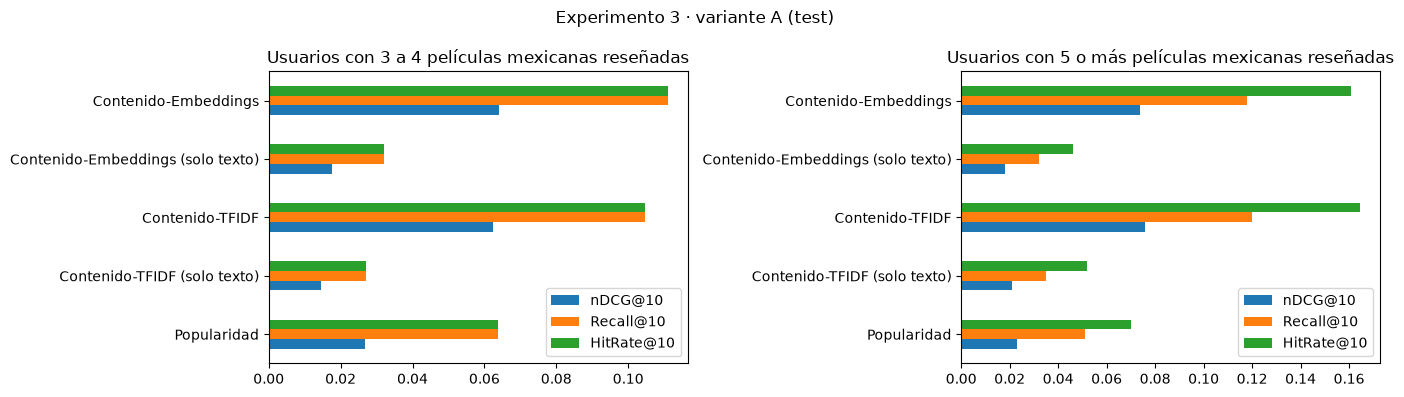

In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4))
for eje, (grupo, r) in zip(ejes, resultados.items()):
    t = r['A']['ranking'].set_index('modelo')[['nDCG@10', 'Recall@10', 'HitRate@10']]
    t.plot.barh(ax=eje)
    eje.set(title=rutas.GRUPOS[grupo]['nombre'], ylabel='')
fig.suptitle('Experimento 3 · variante A (test)')
fig.tight_layout(); fig.savefig(SALIDA / 'metricas_test_variante_A.png', dpi=130)

## 5. Recomendaciones explicables

Una ventaja del contenido es que cada recomendación se puede justificar: *"te la recomiendo porque se parece a X, que calificaste alto"*.

In [10]:
def explicar(grupo, modelo='Contenido-TFIDF', n_usuarios=2, n=5, semilla=3):
    r = resultados[grupo]
    esc, top = r['A']['escenario'], r['A']['tops'][modelo]
    fab, _ = FAMILIAS[modelo]
    mod = fab(r['mejores'][modelo]).ajustar(esc.m)
    titulos = cat.set_index('item')['titulo']
    rng = np.random.default_rng(semilla)
    filas = []
    for e in rng.choice(len(esc.filas), n_usuarios, replace=False):
        fila = esc.filas[e]
        w = mod.pesos(esc.m, np.array([fila]))
        vistos, pesos = w.indices, w.data
        for pos, j in enumerate(top[e, :n], 1):
            aporte = pesos * mod.S[vistos, j]
            k = vistos[np.argmax(aporte)]
            filas.append({'usuario': esc.usuarios_eval[e], 'pos': pos, 'recomendada': titulos.get(esc.catalogo[j]),
                          'porque_se_parece_a': titulos.get(esc.m.items[k], esc.m.items[k]),
                          'relevante_en_test': bool(esc.relevantes[e, j])})
    return pd.DataFrame(filas)

explicar('g5')

,usuario,pos,recomendada,porque_se_parece_a,relevante_en_test
0,angelochaval,1,The Legend of the Chupacabras,The Legend of La Llorona,False
1,angelochaval,2,AAA - The Movie,The Legend of La Llorona,False
2,angelochaval,3,Herod's Law,El Infierno,False
3,angelochaval,4,A Wonderful World,El Infierno,False
4,angelochaval,5,Nikté,The Legend of the Nahuala,False
5,sabinavenus,1,Devil Between the Legs,The Place Without Limits,False
6,sabinavenus,2,Castle of Purity,The Place Without Limits,False
7,sabinavenus,3,No One Writes to the Colonel,The Place Without Limits,False
8,sabinavenus,4,The Black Widow,The Place Without Limits,False
9,sabinavenus,5,Time to Die,Life Sentence,False


## 6. Variantes con sentimiento y significancia

In [11]:
por_usuario = pd.concat([r['A']['por_usuario'].assign(grupo=g) for g, r in resultados.items()] +
                        [v['por_usuario'].assign(grupo=g) for g, r in resultados.items() for v in r['variantes'].values()],
                        ignore_index=True)
significancia = pd.concat([E.comparar_variantes(df, 'A', m).assign(grupo=g)
                           for g, df in por_usuario.groupby('grupo') for m in ('nDCG@10', 'Recall@10')], ignore_index=True)
if len(significancia):
    display(ranking.pivot_table(index=['grupo', 'modelo'], columns='variante', values='nDCG@10'))
    display(significancia)
    val = pd.concat([v['validacion'].assign(grupo=g) for g, r in resultados.items() for v in r['variantes'].values()])
    val.to_csv(SALIDA / 'ajuste_lambda_validacion.csv', index=False)
else:
    print('Aún no hay variantes con sentimiento (ejecuta los notebooks 04 / 05 y vuelve a correr este).')

Aún no hay variantes con sentimiento (ejecuta los notebooks 04 / 05 y vuelve a correr este).


## 7. Guardado

In [12]:
ranking.to_csv(SALIDA / 'ranking_test.csv', index=False)
por_usuario.to_parquet(SALIDA / 'por_usuario_test.parquet', index=False)
significancia.to_csv(SALIDA / 'significancia.csv', index=False)
with open(SALIDA / 'hiperparametros.json', 'w') as f:
    json.dump({g: {'ranking': r['mejores'],
                   'lambda': {v: x['lambda_ranking'] for v, x in r['variantes'].items()}}
               for g, r in resultados.items()}, f, indent=2, default=float)
print('Guardado en', SALIDA)

Guardado en /Users/irving/Documents/TrabajoTerminal/TT_Recomendador_Cine_Mexicano/resultados/exp3


## 8. Lectura de resultados

In [13]:
for grupo, r in resultados.items():
    t = r['A']['ranking'].set_index('modelo')
    mejor = t.drop(index=[m for m in t.index if m == 'Popularidad' or 'solo texto' in m])['nDCG@10'].idxmax()
    print(f"{rutas.GRUPOS[grupo]['nombre']}: mejor = {mejor} (nDCG@10 {t.loc[mejor, 'nDCG@10']:.4f}, "
          f"Recall@10 {t.loc[mejor, 'Recall@10']:.4f}) vs Popularidad (nDCG@10 {t.loc['Popularidad', 'nDCG@10']:.4f}); "
          f"cobertura {t.loc[mejor, 'Cobertura@10']:.0%} vs {t.loc['Popularidad', 'Cobertura@10']:.0%}, "
          f"novedad {t.loc[mejor, 'Novedad@10']:.1f} vs {t.loc['Popularidad', 'Novedad@10']:.1f} bits")
for _, fila in significancia[significancia.metrica == 'nDCG@10'].iterrows() if len(significancia) else []:
    print(f"[{fila.grupo} · {fila.variante}] {fila.modelo}: {fila.mejora_relativa:+.1%} nDCG@10 (p = {fila.p_valor:.3g})")

Usuarios con 3 a 4 películas mexicanas reseñadas: mejor = Contenido-Embeddings (nDCG@10 0.0641, Recall@10 0.1109) vs Popularidad (nDCG@10 0.0269); cobertura 100% vs 2%, novedad 9.0 vs 4.2 bits
Usuarios con 5 o más películas mexicanas reseñadas: mejor = Contenido-TFIDF (nDCG@10 0.0756, Recall@10 0.1199) vs Popularidad (nDCG@10 0.0230); cobertura 100% vs 3%, novedad 6.7 vs 3.5 bits
